# BEAM RL task: 75/25 versus 70/30

Compares the two reward schedules. In 75/25 the good arm of each bandit wins 75% of the time and the bad arm 25%;
in 70/30 they win 70% and 30%. Task length (50 trials per bandit, 100 total), model, parameter sets and seeds are the same.

Recovery results are read from the CSVs written by the two notebooks:

- 75/25: `Simulation_and_Parameter_Recovery.ipynb` → `outputs/`
- 70/30: `Simulation_and_Parameter_Recovery_70_30.ipynb` → `outputs/70_30/`

Run both of those first. The learning curves are re-simulated here with the same seed (about a second), which reproduces
the data in both notebooks exactly. Figures and tables from this notebook go to `outputs/comparison/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import pearsonr, spearmanr

import beam_rl as rl

SEED = 10
OUT = "outputs/comparison"
os.makedirs(OUT, exist_ok=True)

alpha_parameters = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
beta_parameters = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5]

# one entry per reward schedule: win chances, where its notebook saved results, plot colour
CONDITIONS = {
    "75/25": {"p_good": 0.75, "p_bad": 0.25, "dir": "outputs", "color": "#2a78d6"},
    "70/30": {"p_good": 0.70, "p_bad": 0.30, "dir": "outputs/70_30", "color": "#eb6834"},
}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "lines.linewidth": 2})

## 1. Learning

Same ten paired (α, β) groups, 100 agents per group, simulated under each schedule.

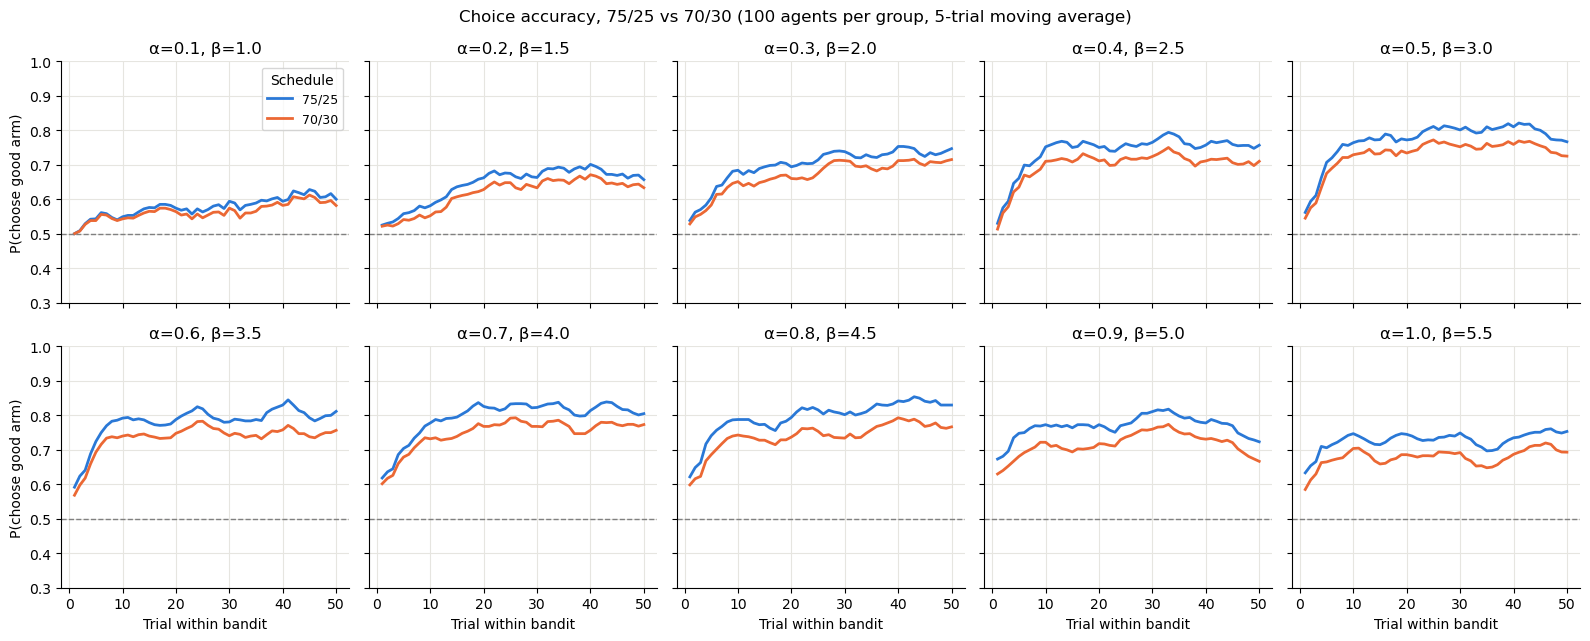

In [2]:
def simulate_paired_groups(agents_per_group, seed, p_good, p_bad):
    rng = np.random.default_rng(seed)
    alphas = np.repeat(alpha_parameters, agents_per_group)
    betas = np.repeat(beta_parameters, agents_per_group)
    data = rl.simulate_group(alphas, betas, rng, p_good=p_good, p_bad=p_bad)
    data["group"] = (data["agent"] - 1) // agents_per_group
    return data

sims = {name: simulate_paired_groups(100, SEED, c["p_good"], c["p_bad"]) for name, c in CONDITIONS.items()}

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharex=True, sharey=True)
for group, ax in enumerate(axes.flat):
    for name, data in sims.items():
        curve = data[data["group"] == group].groupby("pair_trial")["chose_good"].mean()
        smooth = curve.rolling(5, center=True, min_periods=1).mean()
        ax.plot(smooth.index, smooth.values, color=CONDITIONS[name]["color"], label=name)
    ax.axhline(0.5, linestyle="--", linewidth=1, color="grey")
    ax.set_title(f"α={alpha_parameters[group]}, β={beta_parameters[group]}")
    ax.set_ylim(0.3, 1)
for ax in axes[1]:
    ax.set_xlabel("Trial within bandit")
for ax in axes[:, 0]:
    ax.set_ylabel("P(choose good arm)")
axes.flat[0].legend(title="Schedule", fontsize=9)
fig.suptitle("Choice accuracy, 75/25 vs 70/30 (100 agents per group, 5-trial moving average)")
fig.tight_layout()
fig.savefig(f"{OUT}/learning_curves_75_25_vs_70_30.png", dpi=150)
plt.show()

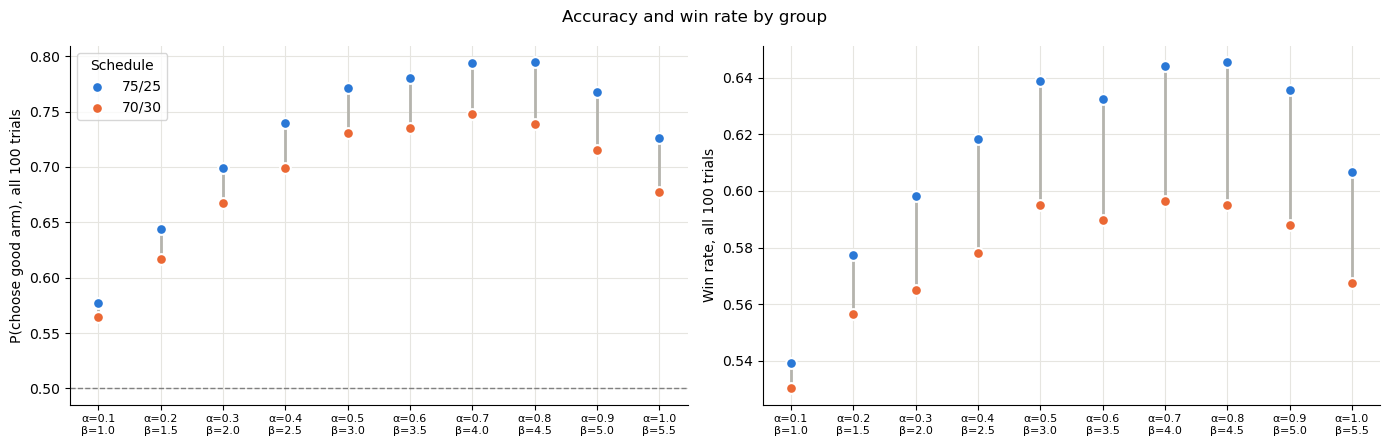

75/25                              70/30                    
             accuracy accuracy_last_10 win_rate accuracy accuracy_last_10   
α=0.1, β=1.0    0.577            0.613    0.539    0.564            0.598  \
α=0.2, β=1.5    0.644            0.670    0.577    0.616            0.644   
α=0.3, β=2.0    0.699            0.740    0.598    0.667            0.711   
α=0.4, β=2.5    0.740            0.762    0.618    0.699            0.713   
α=0.5, β=3.0    0.771            0.795    0.639    0.730            0.751   
α=0.6, β=3.5    0.780            0.806    0.632    0.735            0.748   
α=0.7, β=4.0    0.794            0.823    0.644    0.748            0.776   
α=0.8, β=4.5    0.794            0.842    0.646    0.738            0.777   
α=0.9, β=5.0    0.767            0.755    0.636    0.716            0.702   
α=1.0, β=5.5    0.726            0.750    0.607    0.677            0.704   

                      difference  
             win_rate   accuracy  
α=0.1, β=1.0    0.530     -0.013  
α=0.2, β=1.5    0.556     -0.027  
α=0.3, β=2.0    0.565     -0.032  
α=0.4, β=2.5    0.578     -0.041  
α=0.5, β=3.0    0.595     -0.041  
α=0.6, β=3.5    0.590     -0.045  
α=0.7, β=4.0    0.596     -0.046  
α=0.8, β=4.5    0.595     -0.056  
α=0.9, β=5.0    0.588     -0.052  
α=1.0, β=5.5    0.568     -0.049

In [3]:
def group_summary(data):
    summary = data.groupby("group").agg(alpha=("alpha", "first"), beta=("beta", "first"),
                                        accuracy=("chose_good", "mean"), win_rate=("outcome", "mean"))
    summary["accuracy_last_10"] = data[data["pair_trial"] > 40].groupby("group")["chose_good"].mean()
    return summary

summaries = {name: group_summary(data) for name, data in sims.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(10)
labels = [f"α={a}\nβ={b}" for a, b in zip(alpha_parameters, beta_parameters)]
for ax, column, ylabel in [(axes[0], "accuracy", "P(choose good arm), all 100 trials"),
                           (axes[1], "win_rate", "Win rate, all 100 trials")]:
    a, b = summaries["75/25"][column], summaries["70/30"][column]
    ax.vlines(x, np.minimum(a, b), np.maximum(a, b), color="#b5b4ad", linewidth=2, zorder=1)
    for name, values in [("75/25", a), ("70/30", b)]:
        ax.scatter(x, values, s=60, color=CONDITIONS[name]["color"], edgecolor="white",
                   linewidth=1.5, zorder=2, label=name)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel(ylabel)
axes[0].axhline(0.5, linestyle="--", linewidth=1, color="grey")
axes[0].legend(title="Schedule")
fig.suptitle("Accuracy and win rate by group")
fig.tight_layout()
fig.savefig(f"{OUT}/accuracy_by_group_75_25_vs_70_30.png", dpi=150)
plt.show()

learning_table = pd.concat({name: s[["accuracy", "accuracy_last_10", "win_rate"]] for name, s in summaries.items()}, axis=1)
learning_table.index = [f"α={a}, β={b}" for a, b in zip(alpha_parameters, beta_parameters)]
learning_table[("difference", "accuracy")] = learning_table[("70/30", "accuracy")] - learning_table[("75/25", "accuracy")]
learning_table.to_csv(f"{OUT}/learning_75_25_vs_70_30.csv")
learning_table.round(3)

## 2. Parameter recovery

Recovery statistics for each schedule, on the paired groups, the crossed grid at 100 trials (the task design) and the
crossed grid at 200 trials. The 95% intervals come from resampling agents (1,000 bootstrap samples).

In [4]:
def load(name, file):
    return pd.read_csv(f"{CONDITIONS[name]['dir']}/{file}")

RUNS = {"paired groups": "recovery_paired_groups.csv",
        "crossed, 100 trials": "recovery_crossed_100_trials.csv",
        "crossed, 200 trials": "recovery_crossed_200_trials.csv"}
results = {(name, run): load(name, file) for name in CONDITIONS for run, file in RUNS.items()}

def recovery_stats(r):
    return {"alpha_pearson": pearsonr(r["alpha_true"], r["alpha_hat"])[0],
            "alpha_spearman": spearmanr(r["alpha_true"], r["alpha_hat"])[0],
            "beta_pearson": pearsonr(r["beta_true"], r["beta_hat"])[0],
            "beta_spearman": spearmanr(r["beta_true"], r["beta_hat"])[0],
            "alpha_median_abs_error": (r["alpha_hat"] - r["alpha_true"]).abs().median(),
            "beta_median_abs_error": (r["beta_hat"] - r["beta_true"]).abs().median(),
            "beta_at_upper_bound": (r["beta_hat"] > rl.BETA_BOUNDS[1] - 0.01).mean(),
            "alpha_at_a_bound": ((r["alpha_hat"] < 0.01) | (r["alpha_hat"] > 0.99)).mean()}

metrics = pd.DataFrame({key: recovery_stats(r) for key, r in results.items()})
metrics.to_csv(f"{OUT}/recovery_metrics_75_25_vs_70_30.csv")
metrics.round(3)

75/25                                           
                       paired groups crossed, 100 trials crossed, 200 trials   
alpha_pearson                  0.796               0.831               0.913  \
alpha_spearman                 0.788               0.829               0.913   
beta_pearson                   0.361               0.463               0.554   
beta_spearman                  0.668               0.786               0.895   
alpha_median_abs_error         0.091               0.093               0.064   
beta_median_abs_error          0.587               0.554               0.342   
beta_at_upper_bound            0.100               0.040               0.018   
alpha_at_a_bound               0.153               0.120               0.089   

                               70/30                                          
                       paired groups crossed, 100 trials crossed, 200 trials  
alpha_pearson                  0.787               0.820               0.913  
alpha_spearman                 0.782               0.819               0.913  
beta_pearson                   0.400               0.449               0.537  
beta_spearman                  0.654               0.766               0.886  
alpha_median_abs_error         0.095               0.090               0.063  
beta_median_abs_error          0.709               0.600               0.371  
beta_at_upper_bound            0.114               0.041               0.020  
alpha_at_a_bound               0.148               0.124               0.101

In [5]:
# Bootstrap intervals for the main measures, resampling agents with replacement.
MAIN = [("alpha_pearson", "α: Pearson r"), ("beta_spearman", "β: Spearman ρ"),
        ("alpha_median_abs_error", "α: median |error|"), ("beta_median_abs_error", "β: median |error|")]
N_BOOT = 1000
boot_rng = np.random.default_rng(SEED + 100)

def bootstrap(r):
    draws = []
    for _ in range(N_BOOT):
        sample = r.iloc[boot_rng.integers(0, len(r), len(r))]
        s = recovery_stats(sample)
        draws.append({key: s[key] for key, _ in MAIN})
    return pd.DataFrame(draws)

boots = {key: bootstrap(r) for key, r in results.items() if key[1] != "paired groups"}

rows = []
for run in ["crossed, 100 trials", "crossed, 200 trials"]:
    a, b = boots[("75/25", run)], boots[("70/30", run)]
    for key, label in MAIN:
        diff = b[key] - a[key]  # 70/30 minus 75/25
        rows.append({"run": run, "measure": label,
                     "75/25": metrics.loc[key, ("75/25", run)], "70/30": metrics.loc[key, ("70/30", run)],
                     "difference (70/30 - 75/25)": metrics.loc[key, ("70/30", run)] - metrics.loc[key, ("75/25", run)],
                     "diff 95% low": diff.quantile(0.025), "diff 95% high": diff.quantile(0.975)})
differences = pd.DataFrame(rows)
differences.to_csv(f"{OUT}/recovery_differences_75_25_vs_70_30.csv", index=False)
differences.round(3)

,run,measure,75/25,70/30,difference (70/30 - 75/25),diff 95% low,diff 95% high
0,"crossed, 100 trials",α: Pearson r,0.831,0.820,-0.010,-0.031,0.012
1,"crossed, 100 trials",β: Spearman ρ,0.786,0.766,-0.019,-0.049,0.012
2,"crossed, 100 trials",α: median |error|,0.093,0.090,-0.003,-0.009,0.002
3,"crossed, 100 trials",β: median |error|,0.554,0.600,0.046,0.006,0.089
4,"crossed, 200 trials",α: Pearson r,0.913,0.913,0.000,-0.013,0.014
5,"crossed, 200 trials",β: Spearman ρ,0.895,0.886,-0.008,-0.029,0.016
6,"crossed, 200 trials",α: median |error|,0.064,0.063,-0.001,-0.005,0.003
7,"crossed, 200 trials",β: median |error|,0.342,0.371,0.029,0.003,0.051


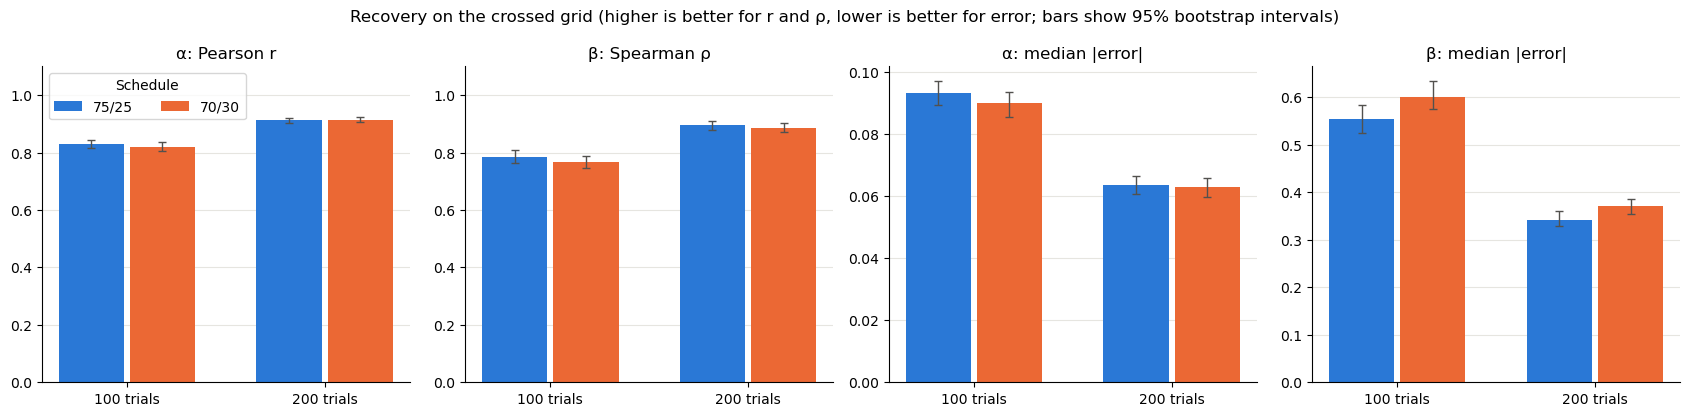

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
runs = ["crossed, 100 trials", "crossed, 200 trials"]
width = 0.36
for ax, (key, label) in zip(axes, MAIN):
    for offset, name in [(-width / 2, "75/25"), (width / 2, "70/30")]:
        values = [metrics.loc[key, (name, run)] for run in runs]
        low = [values[i] - boots[(name, run)][key].quantile(0.025) for i, run in enumerate(runs)]
        high = [boots[(name, run)][key].quantile(0.975) - values[i] for i, run in enumerate(runs)]
        ax.bar(np.arange(2) + offset, values, width - 0.03, color=CONDITIONS[name]["color"], label=name)
        ax.errorbar(np.arange(2) + offset, values, yerr=[low, high], fmt="none", ecolor="#52514e", capsize=3, linewidth=1)
    ax.set_xticks(range(2))
    ax.set_xticklabels(["100 trials", "200 trials"])
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
axes[0].set_ylim(0, 1.1)
axes[1].set_ylim(0, 1.1)
axes[0].legend(title="Schedule", loc="upper left", ncol=2)
fig.suptitle("Recovery on the crossed grid (higher is better for r and ρ, lower is better for error; bars show 95% bootstrap intervals)")
fig.tight_layout()
fig.savefig(f"{OUT}/recovery_metrics_75_25_vs_70_30.png", dpi=150)
plt.show()

### Bias: median recovered value against the true value

Crossed grid, 100 trials. Lines are medians, bands the interquartile range, the dashed line is perfect recovery.

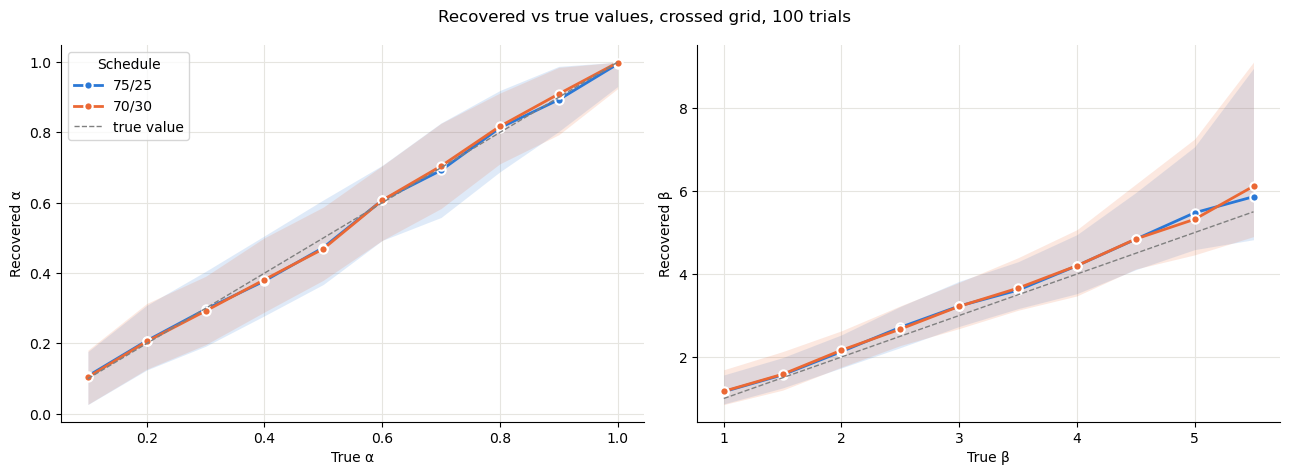

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, true_col, hat_col, label in [(axes[0], "alpha_true", "alpha_hat", "α"),
                                     (axes[1], "beta_true", "beta_hat", "β")]:
    for name in CONDITIONS:
        r = results[(name, "crossed, 100 trials")]
        q = r.groupby(true_col)[hat_col].quantile([0.25, 0.5, 0.75]).unstack()
        color = CONDITIONS[name]["color"]
        ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.15, linewidth=0)
        ax.plot(q.index, q[0.5], color=color, marker="o", markersize=6,
                markeredgecolor="white", markeredgewidth=1.5, label=name)
    values = sorted(r[true_col].unique())
    ax.plot(values, values, linestyle="--", linewidth=1, color="grey", label="true value")
    ax.set_xlabel(f"True {label}")
    ax.set_ylabel(f"Recovered {label}")
axes[0].legend(title="Schedule")
fig.suptitle("Recovered vs true values, crossed grid, 100 trials")
fig.tight_layout()
fig.savefig(f"{OUT}/recovery_bias_75_25_vs_70_30.png", dpi=150)
plt.show()

### Where the change hurts: difference in median error per cell

Each cell is (median |error| under 70/30) − (median |error| under 75/25) for one (α, β) combination, crossed grid,
100 trials. Orange cells are worse under 70/30, purple cells better. The colour scale is capped at the 95th
percentile of the differences, so the most extreme cells (near α = 1, where β is unidentified) show at full colour. Each cell has 30 agents per schedule, so single
cells are noisy; look for regions rather than individual cells.

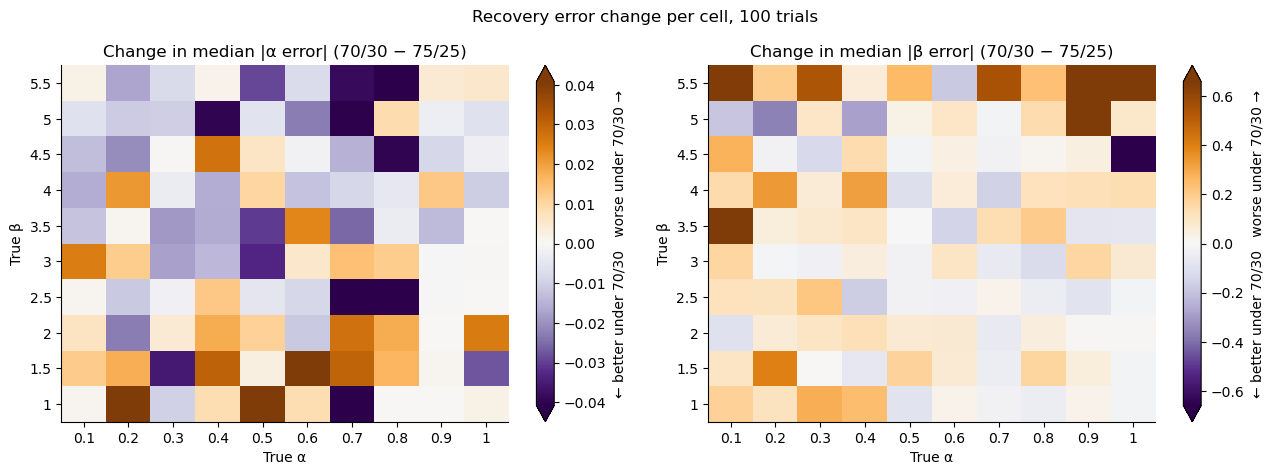

In [8]:
def median_abs_error_table(r, true_col, hat_col):
    err = (r[hat_col] - r[true_col]).abs()
    return r.assign(err=err).pivot_table(index="beta_true", columns="alpha_true", values="err", aggfunc="median")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, param, label in [(axes[0], "alpha", "α"), (axes[1], "beta", "β")]:
    tables = {name: median_abs_error_table(results[(name, "crossed, 100 trials")], f"{param}_true", f"{param}_hat")
              for name in CONDITIONS}
    diff = tables["70/30"] - tables["75/25"]
    # cap the colour scale at the 95th percentile so a few extreme cells (alpha near 1,
    # where beta is unidentified) do not wash out the rest; arrows on the bar mark the cap
    limit = np.nanpercentile(np.abs(diff.values), 95)
    image = ax.imshow(diff.values, origin="lower", aspect="auto", cmap="PuOr_r",
                      norm=TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit))
    ax.set_xticks(range(len(diff.columns)))
    ax.set_xticklabels([f"{v:g}" for v in diff.columns])
    ax.set_yticks(range(len(diff.index)))
    ax.set_yticklabels([f"{v:g}" for v in diff.index])
    ax.set_xlabel("True α")
    ax.set_ylabel("True β")
    ax.set_title(f"Change in median |{label} error| (70/30 − 75/25)")
    ax.grid(False)
    fig.colorbar(image, ax=ax, extend="both", label="← better under 70/30   worse under 70/30 →")
fig.suptitle("Recovery error change per cell, 100 trials")
fig.tight_layout()
fig.savefig(f"{OUT}/recovery_error_difference_heatmap_100_trials.png", dpi=150)
plt.show()

## Summary

**Learning.** Every group picks the good arm less often under 70/30: 1 to 6 percentage points lower, with the
biggest drops in the high-α groups (α = 0.8: 79% → 74%). Win rates fall by 1 to 5 points. Learning curves have the
same shape and the same speed; the plateau is lower.

**Recovery (crossed grid, 100 trials).**

| Measure | 75/25 | 70/30 | Difference (95% bootstrap interval) |
| --- | --- | --- | --- |
| α Pearson r | 0.83 | 0.82 | −0.01 (−0.03 to +0.01) |
| β Spearman ρ | 0.79 | 0.77 | −0.02 (−0.05 to +0.01) |
| Median abs error, α | 0.093 | 0.090 | −0.003 (−0.009 to +0.002) |
| Median abs error, β | 0.55 | 0.60 | +0.05 (+0.01 to +0.09) |
| β fits at upper bound | 4.0% | 4.1% | |
| α fits at 0 or 1 | 12.0% | 12.4% | |

- α recovery is unchanged. The per-cell α differences are a checkerboard of ±0.04 with no pattern, i.e. noise.
- β gets slightly worse: median error up about 8% (0.55 → 0.60), and the interval excludes zero. The increase is spread
  across most of the grid and is largest at high β, which is expected: with outcomes closer to 50/50 the gap between
  the two Q-values is smaller, so the same β produces less distinct choice behaviour.
- At 200 trials the pattern is the same (α identical, β median error 0.34 → 0.37).
- Recovery on the paired groups: α r 0.80 → 0.79, β ρ 0.67 → 0.65.

**Reading.** Moving from 75/25 to 70/30 makes the task a bit harder for the agents but barely changes how well
the parameters can be estimated. The conclusions from 75/25 still hold: α is recovered well, β is right on
average but noisy for individuals, and the weak spots are still α near 1 and β near 1.
